<div dir="rtl">

# بوصلة العطاء — حصر المناطق الـ13 ومقارنة الملفات المتاحة

**حالة النسخة: ملفات المناطق الـ13 مقروءة، مع نقص الأرقام الوطنية في مصدر الجوف.**

أرفق صاحب المشروع ملفات CSV وExcel صحيحة لعسير والجوف بعد تعذر التنزيل السابق. حُفظت الملفات الأربعة دون تغيير، وتطابقت كل خلايا البيانات بين الصيغتين لكل منطقة. بقيت التنزيلات المرفوضة محفوظة كأثر جمع سابق ولم تستخدم في التحليل.

النسخة المنفذة تضم **6,403 سجلات جهات من 13 منطقة**: 6,341 سجلاً بأرقام وطنية فريدة، و62 سجلًا للجوف دون حقل الرقم الوطني في الأصل. لم نخترع أرقاماً لها؛ `record_key` مفتاح صف داخل المشروع فقط. العد للسجلات، ولا يؤكد تفرّد الجهات بلا معرّف عبر المملكة.

الأعداد حسب **منطقة مجموعة المصدر**، وليست تحققاً من مقر كل جهة أو نطاق خدماتها. نحتفظ بنسخة القصيم ونسخة 11 منطقة السابقتين للرجوع.

</div>

<div dir="rtl">

## 1. تجهيز البيئة

اقرأ المخرجات المحفوظة مباشرة، أو شغّل الخلايا بالترتيب. في Colab ارفع حزمة `bouslat-alataa-national.zip` وفكّها باستخدام:

`!unzip -q -o /content/bouslat-alataa-national.zip -d /content`

التحليل لا يستدعي نموذجاً أو API مدفوعة. خلية التثبيت وحدها تحتاج الإنترنت؛ قراءة المصادر تتم من ملفات الحزمة. لا تشغّل أدوات التنزيل لإعادة التحليل.

</div>

In [1]:
import sys
if "google.colab" in sys.modules:
    import subprocess
    subprocess.check_call([sys.executable,"-m","pip","install","-q",
                           "pandas==3.0.1","numpy==2.5.4","matplotlib==3.11.2","openpyxl==3.1.5"])
else:
    print("محلياً: ثبّت requirements.txt في بيئة مستقلة قبل التشغيل.")

محلياً: ثبّت requirements.txt في بيئة مستقلة قبل التشغيل.


In [2]:
from pathlib import Path
from collections import Counter
import csv
import hashlib
import io
import json
import re
import textwrap
import unicodedata
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager

LICENSE_URL="https://open.data.gov.sa/ar/pages/policies/license"


def project_root():
    cwd=Path.cwd()
    for path in [cwd,cwd/"bouslat-alataa-national",*cwd.parents]:
        if (path/"research/national_sources.json").is_file():
            return path
    raise FileNotFoundError("استخرج حزمة المشروع التي تحتوي research/national_sources.json أولاً.")

EXPECTED_COLUMNS = ['الرقم الوطني الموحد', 'اسم الكيان', 'المدينة', 'التصنيف النوعي', 'التصنيف الفرعي الاول', 'التصنيف الفرعي الثاني', 'نوع الكيان', 'جهة الإشراف']

In [3]:
ROOT=project_root()
REQUIRE_ALL_REGIONS=True  # نطلب ملفات المناطق الـ13؛ هذا لا يعني اكتمال الأرقام الوطنية.
rules=json.loads((ROOT/"config/national_mappings.json").read_text(encoding="utf-8"))
pd.set_option("display.max_colwidth",100)
print("Project:",ROOT.name)

Project: Data Analysis


<div dir="rtl">

## 2. المصدر والرخصة وتوافق التاريخ

الناشر: **المركز الوطني لتنمية القطاع غير الربحي**. حُصرت المصادر من [فهرس المنصة الوطنية](https://open.data.gov.sa/ar/datasets) بالبحث «الكيانات غير الربحية». جميع البطاقات الـ13 تربط [رخصة البيانات المفتوحة](https://open.data.gov.sa/ar/pages/policies/license). توجد نسخة الرخصة في الحزمة، والروابط المفصلة والبصمات في `research/national_sources.json`.

تاريخ التحقق: **23 أكتوبر 2026**. تعرض الجوف فترة مرجعية لعام 2025 وتحديثاً في أغسطس 2025. عسير تعرض فترة ممتدة من نوفمبر 2025 إلى نهاية 2026. أغلب بقية الملفات تعرض عام 2026 وتحديثاً في مارس 2026. هذه بيانات وصفية للمجموعات، ولا يحتوي CSV تاريخ ملاحظة لكل كيان.

نستبعد مجموعة الرياض القديمة البديلة من الدمج؛ نستخدم المصدر الإقليمي الأحدث فقط. لا نخلط دليل نوى مع هذه الملفات المرخصة.

عسير وتبوك ونجران بترميز Windows-1256؛ ظهور الحروف كطلاسم في برنامج آخر لا يعني تلف المصدر. الجوف UTF-8 وتحتوي 7 أعمدة دون الرقم الوطني، بينما بقية المناطق 8 أعمدة.

القارئ التالي يرفض HTML حتى لو كان امتداد الملف CSV، ويفحص البصمة ورأس الأعمدة. يقبل مخطط الجوف ذي الأعمدة السبعة صراحةً، ويترك المعرّف غير المنشور فارغاً في النسخة الموحدة. لا يملأه باسم الكيان أو بمفتاح الصف.

</div>

In [4]:
def verify_source_pairs(root):
    import openpyxl
    comparisons=json.loads((root/"research/user_supplied_comparison.json").read_text(encoding="utf-8"))["comparisons"]
    results=[]
    for comparison in comparisons:
        attachments={item["format"]:item for item in comparison["attachments"]}
        for attachment in attachments.values():
            if hashlib.sha256((root/attachment["local_file"]).read_bytes()).hexdigest()!=attachment["sha256"]:
                raise ValueError("Attached original bytes changed: "+attachment["local_file"])
        text=(root/attachments["CSV"]["local_file"]).read_bytes().decode(comparison["encoding"],errors="strict")
        csv_rows=[row for row in csv.reader(io.StringIO(text,newline="")) if any(value.strip() for value in row)]
        workbook=openpyxl.load_workbook(root/attachments["XLSX"]["local_file"],read_only=True,data_only=False)
        sheet=workbook[comparison["sheet_compared"]]
        xlsx_rows=[]
        for cells in sheet.iter_rows():
            if any(cell.data_type=="f" for cell in cells):
                raise ValueError("Unexpected formula in original data sheet")
            values=[]
            for cell in cells:
                value=cell.value
                if value is None:
                    value=""
                elif isinstance(value,float) and value.is_integer():
                    value=str(int(value))
                else:
                    value=str(value)
                values.append(value)
            if any(value.strip() for value in values):
                xlsx_rows.append(values)
        workbook.close()
        if csv_rows!=xlsx_rows or len(csv_rows)-1!=comparison["data_records"]:
            raise AssertionError("CSV/XLSX cell comparison failed: "+comparison["region"])
        results.append({"region":comparison["region"],"data_records":len(csv_rows)-1,
                        "csv_xlsx_all_cells_equal":True,"all_four_source_files_unchanged":True,
                        "national_id_column_present":"الرقم الوطني الموحد" in csv_rows[0]})
    return results


display(pd.DataFrame(verify_source_pairs(ROOT)))

,region,data_records,csv_xlsx_all_cells_equal,all_four_source_files_unchanged,national_id_column_present
0,عسير,536,True,True,True
1,الجوف,62,True,True,False


In [5]:
def read_regional_source(root, source):
    path = root / source["local_file"]
    payload = path.read_bytes()
    if hashlib.sha256(payload).hexdigest() != source["source_sha256"]:
        raise ValueError("Source hash changed: " + source["region"])
    if payload.lstrip().lower().startswith((b"<html", b"<!doctype html")):
        raise ValueError("DOWNLOAD_RETURNED_HTML_REQUEST_REJECTED")
    encoding = "utf-8-sig"
    try:
        text = payload.decode(encoding)
    except UnicodeDecodeError:
        encoding = "cp1256"
        text = payload.decode(encoding, errors="strict")
    records = list(csv.reader(io.StringIO(text, newline="")))
    expected=source.get("source_columns_expected",EXPECTED_COLUMNS)
    if expected not in [EXPECTED_COLUMNS,EXPECTED_COLUMNS[1:]]:
        raise ValueError("UNREVIEWED_SOURCE_SCHEMA")
    headers = [i for i, row in enumerate(records) if [x.strip() for x in row] == expected]
    if len(headers) != 1:
        raise ValueError("UNEXPECTED_SCHEMA")
    header_index = headers[0]
    if any(any(cell.strip() for cell in row) for row in records[:header_index]):
        raise ValueError("NONEMPTY_RECORD_BEFORE_HEADER")
    body = []
    for index, row in enumerate(records[header_index + 1:], header_index + 2):
        if not any(cell.strip() for cell in row):
            continue
        if len(row) != len(expected):
            raise ValueError(f"MALFORMED_WIDTH:{index}")
        record=dict(zip(expected,row))
        # Blank means unpublished, never a generated national identifier.
        record.setdefault("الرقم الوطني الموحد","")
        body.append({**record,"source_record":index})
    return body, {
        "encoding": encoding, "source_header": records[header_index],
        "header_record": header_index + 1, "csv_records": len(records),
        "blank_format_records": len(records) - len(body) - 1,
        "source_columns":expected,"column_count":len(expected),
        "identifier_column_present":"الرقم الوطني الموحد" in expected,
    }


def load_sources(root, require_all_regions=True):
    manifest=json.loads((root/"research/national_sources.json").read_text(encoding="utf-8"))
    frames, inventory=[],[]
    for source in manifest["sources"]:
        entry={key:source[key] for key in ["region","slug","dataset_url","updated_at_as_displayed","reference_period_as_displayed","local_file"]}
        try:
            rows, details=read_regional_source(root,source)
        except ValueError as error:
            entry.update(status="unavailable",reason=str(error),records=None,encoding=None)
        else:
            frame=pd.DataFrame(rows,dtype=object)
            frame["source_region"]=source["region"]
            frame["source_slug"]=source["slug"]
            frame["source_dataset_id"]=source["dataset_id"]
            frame["source_dataset_url"]=source["dataset_url"]
            frame["source_updated_at"]=source["updated_at_as_displayed"]
            frame["source_reference_period"]=source["reference_period_as_displayed"]
            frame["source_has_national_id"]=details["identifier_column_present"]
            frame["record_key"]=source["slug"]+":"+frame["source_record"].astype(str)
            frames.append(frame)
            entry.update(status="readable",reason="",records=len(frame),**details)
        inventory.append(entry)
    inventory=pd.DataFrame(inventory)
    missing=inventory.loc[inventory.status.ne("readable"),"region"].tolist()
    if require_all_regions and missing:
        raise ValueError("لا يمكن اعتماد تغطية 13/13؛ المصادر غير المتاحة: "+"، ".join(missing))
    if not frames:
        raise ValueError("لا توجد ملفات صالحة للتحليل.")
    return pd.concat(frames,ignore_index=True),inventory,manifest

In [6]:
raw,inventory,manifest=load_sources(ROOT,REQUIRE_ALL_REGIONS)
columns=["region","status","records","column_count","identifier_column_present","encoding","updated_at_as_displayed","reference_period_as_displayed"]
display(inventory[columns].astype(object).where(pd.notna(inventory[columns]),"غير متاح"))
print("Readable regions:",inventory.status.eq("readable").sum(),"/13; records:",len(raw))
display(raw.head(5))

,region,status,records,column_count,identifier_column_present,encoding,updated_at_as_displayed,reference_period_as_displayed
0,الرياض,readable,1683,8,True,utf-8-sig,2026-03-09 11:10:00,2026-01-01 - 2026-12-31
1,مكة المكرمة,readable,1365,8,True,utf-8-sig,2026-03-09 11:09:48,2026-01-01 - 2026-12-31
2,المدينة المنورة,readable,384,8,True,utf-8-sig,2026-03-09 11:16:28,2026-01-01 - 2026-12-31
3,القصيم,readable,562,8,True,utf-8-sig,2026-03-09 11:06:33,2026-01-01 - 2026-12-31
4,الشرقية,readable,524,8,True,utf-8-sig,2026-03-09 11:08:10,2026-01-01 - 2026-12-31
5,عسير,readable,536,8,True,cp1256,2026-03-04 13:25:25,2025-11-01 - 2026-12-31
6,تبوك,readable,143,8,True,cp1256,2026-03-05 14:33:11,2026-01-01 - 2026-12-31
7,حائل,readable,365,8,True,utf-8-sig,2026-03-09 11:08:25,2026-01-01 - 2026-12-31
8,الحدود الشمالية,readable,133,8,True,utf-8-sig,2026-03-09 11:06:14,2026-01-01 - 2026-12-31
9,جازان,readable,305,8,True,utf-8-sig,2026-03-09 11:09:33,2026-01-01 - 2026-12-31


Readable regions: 13 /13; records: 6403


,الرقم الوطني الموحد,اسم الكيان,المدينة,التصنيف النوعي,التصنيف الفرعي الاول,التصنيف الفرعي الثاني,نوع الكيان,جهة الإشراف,source_record,source_region,source_slug,source_dataset_id,source_dataset_url,source_updated_at,source_reference_period,source_has_national_id,record_key
0,7028296213,فلك لعلوم وأبحاث الفضاء,مدينة الرياض,المجموعة الثانية التعليم والأبحاث (المنظمات والأنشطة التي تقود وتدير وتقدم وتشجع وتدعم الخدمات ا...,الأبحاث,الأبحاث والعلوم والتقنية في الفضاء اوالفلك,جمعية أهلية,وكالة الفضاء السعودية,3,الرياض,riyadh,6442df92-588e-49a0-9776-6a6992967d94,https://open.data.gov.sa/ar/datasets/view/6442df92-588e-49a0-9776-6a6992967d94,2026-03-09 11:10:00,2026-01-01 - 2026-12-31,True,riyadh:3
1,7053492190,إسناد المسافرين,محافظة الأفلاج,المجموعة السادسة التنمية و الإسكان (المنظمات التي تعزز البرامج و الخدمات للمساعدة في تحسين المجت...,التنمية الاجتماعية والاقتصادية والمجتمعية,منظمات النقل البري,جمعية أهلية,وزارة النقل والخدمات اللوجستية,4,الرياض,riyadh,6442df92-588e-49a0-9776-6a6992967d94,https://open.data.gov.sa/ar/datasets/view/6442df92-588e-49a0-9776-6a6992967d94,2026-03-09 11:10:00,2026-01-01 - 2026-12-31,True,riyadh:4
2,7051690969,النقل المستدام و اللوجستيات,مدينة الرياض,المجموعة السادسة التنمية و الإسكان (المنظمات التي تعزز البرامج و الخدمات للمساعدة في تحسين المجت...,المسؤولية الاجتماعية في قطاع النقل,منظمات المسؤولية الاجتماعية في قطاع النقل البري والجوي والبحري والسككي,جمعية أهلية,وزارة النقل والخدمات اللوجستية,5,الرياض,riyadh,6442df92-588e-49a0-9776-6a6992967d94,https://open.data.gov.sa/ar/datasets/view/6442df92-588e-49a0-9776-6a6992967d94,2026-03-09 11:10:00,2026-01-01 - 2026-12-31,True,riyadh:5
3,7030206473,أمان للوقاية من الحوادث المرورية,مدينة الرياض,المجموعة الثانية التعليم والأبحاث (المنظمات والأنشطة التي تقود وتدير وتقدم وتشجع وتدعم الخدمات ا...,الأبحاث,الخدمات الاستشارية وأبحاث النقل والسلامة,جمعية أهلية,وزارة النقل والخدمات اللوجستية,6,الرياض,riyadh,6442df92-588e-49a0-9776-6a6992967d94,https://open.data.gov.sa/ar/datasets/view/6442df92-588e-49a0-9776-6a6992967d94,2026-03-09 11:10:00,2026-01-01 - 2026-12-31,True,riyadh:6
4,8000002968,جمعية الطيران السعودية,مدينة الرياض,المجموعة السادسة التنمية و الإسكان (المنظمات التي تعزز البرامج و الخدمات للمساعدة في تحسين المجت...,العمل والتدريب,منظمات تدريب الطيران,جمعية أهلية,وزارة النقل والخدمات اللوجستية,7,الرياض,riyadh,6442df92-588e-49a0-9776-6a6992967d94,https://open.data.gov.sa/ar/datasets/view/6442df92-588e-49a0-9776-6a6992967d94,2026-03-09 11:10:00,2026-01-01 - 2026-12-31,True,riyadh:7


<div dir="rtl">

## 3. قرارات التوحيد والمراجعة

- المواقع: خريطة صريحة توحد المسافات وأخطاء إملائية محددة، وتحفظ «مدينة/محافظة/مركز». لا دمج بالتشابه، ولا استنتاج للمقر من اسم الكيان.
- المجموعات الرئيسية: اعتماد الرقم والاسم المنشورين مع إبقاء الأوصاف الأصلية. البيئة تتضمن أوصافاً متعارضة تحتاج مراجعة.
- `منشأة بأمر ملكي` و`HMS_Check`: خارج المجموعات العشر؛ تظهران منفصلتين ولا تُحوّلان إلى تخصص مفترض.
- **مكة:** التصنيف الفرعي الأول يطابق الثاني في 1,365/1,365 سجلاً. نحتفظ بالعمودين لكن لا نستخدم المستوى الأول للمقارنة بين المناطق.
- سجلات مواقع تحمل أسماء تظهر في ملفات مناطق أخرى: تُعلّم للمراجعة، ولا ننقلها بين المناطق.
- الخلايا الأصلية الفارغة تبقى فارغة؛ لا ملء بتخمين.
- الجوف: حقل المعرّف الوطني غير منشور، ونوع الوحدة الجغرافية غير مذكور. يبقى الأصل محفوظاً دون افتراض مدينة أو محافظة. سجل المشكلات يرتبط بمفتاح صف، لا بالمعرّف الوطني الفارغ.

هذه قرارات تحليل موثقة في `config/national_mappings.json`، وليست تصحيحات اعتمدها الناشر.

</div>

In [7]:
display(raw.groupby("source_region").apply(lambda g:pd.Series({
    "السجلات":len(g),
    "تطابق التصنيفين الفرعيين":int(g["التصنيف الفرعي الاول"].eq(g["التصنيف الفرعي الثاني"]).sum())
})))
display(pd.DataFrame([{"القيمة الأصلية":value,**rule} for value,rule in rules["main_groups"].items()]))
display(pd.DataFrame(rules["location_cross_file_review"]))

,السجلات,تطابق التصنيفين الفرعيين
source_region,,
الباحة,202,14
الجوف,62,4
الحدود الشمالية,133,5
الرياض,1683,232
الشرقية,524,59
القصيم,562,33
المدينة المنورة,384,16
تبوك,143,6
جازان,305,13


,القيمة الأصلية,code,name,description_review,reason
0,المجموعة الأولى : الثقافة والترفيه (المنظمات والأنشطة المتخصصة في الثقافة والترفيه),G01,الثقافة والترفيه,False,توحيد العنوان وفق رقم المجموعة واسمها المنشورين؛ الوصف الأصلي محفوظ.
1,المجموعة التاسعة منظمات الدعوة والإرشاد والتعليم الديني وخدمة ضيوف الرحمن (المنظمات التي تعمل عل...,G09,منظمات الدعوة والإرشاد والتعليم الديني وخدمة ضيوف الرحمن,False,توحيد العنوان وفق رقم المجموعة واسمها المنشورين؛ الوصف الأصلي محفوظ.
2,المجموعة الثالثة الصحة (المنظمات التي تعمل في الأنشطة التي لها علاقة بالصحة وتوفير الرعاية الصحي...,G03,الصحة,False,توحيد العنوان وفق رقم المجموعة واسمها المنشورين؛ الوصف الأصلي محفوظ.
3,المجموعة الثامنة منظمات دعم العمل الخيري (المنظمات التي تقدم أنواع الدعم المختلفة للعمل الخيري و...,G08,منظمات دعم العمل الخيري,False,توحيد العنوان وفق رقم المجموعة واسمها المنشورين؛ الوصف الأصلي محفوظ.
4,المجموعة الثانية التعليم والأبحاث (المنظمات والأنشطة التي تقود وتدير وتقدم وتشجع وتدعم الخدمات ا...,G02,التعليم والأبحاث,False,توحيد العنوان وفق رقم المجموعة واسمها المنشورين؛ الوصف الأصلي محفوظ.
5,المجموعة الخامسة البيئة (المنظمات التي تعزز وتوفر الخدمات التي تٌعنى بالمحافظة على البيئة ومكافح...,G05,البيئة,False,توحيد العنوان وفق رقم المجموعة واسمها المنشورين؛ الوصف الأصلي محفوظ.
6,المجموعة الخامسة البيئة (المنظمات التي تقدم خدمات إنسانية واجتماعية للمجتمع لفئات مستهدفة),G05,البيئة,True,الرقم والاسم يحددان مجموعة البيئة، لكن الوصف بين القوسين يصف خدمات اجتماعية؛ حُفظ النص الأصلي وأ...
7,المجموعة الرابعة الخدمات الاجتماعية (المنظمات التي تقدم خدمات إنسانية واجتماعية للمجتمع لفئات مس...,G04,الخدمات الاجتماعية,False,توحيد العنوان وفق رقم المجموعة واسمها المنشورين؛ الوصف الأصلي محفوظ.
8,المجموعة السابعة التأييد والمؤازرة(المنظمات التي تعمل على حماية وتعزيز حقوق فئات معينة، تقديم ال...,G07,التأييد والمؤازرة,False,توحيد العنوان وفق رقم المجموعة واسمها المنشورين؛ الوصف الأصلي محفوظ.
9,المجموعة السادسة التنمية و الإسكان (المنظمات التي تعزز البرامج و الخدمات للمساعدة في تحسين المجت...,G06,التنمية والإسكان,False,توحيد العنوان وفق رقم المجموعة واسمها المنشورين؛ الوصف الأصلي محفوظ.


,region,location_label,also_seen_in
0,حائل,محافظة العلا,المدينة المنورة
1,الحدود الشمالية,محافظة حفر الباطن,الشرقية
2,جازان,مدينة الرياض,الرياض
3,الباحة,محافظة جدة,مكة المكرمة
4,الجوف,الرياض,الرياض


In [8]:
def normalize_text(value):
    """NFC and whitespace only; never globally fold distinct Arabic letters."""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", value)).strip()


def clean_entities(raw, record_numbers, rules, audit_keys=None):
    """Apply explicit mappings, preserve all original columns, log changes."""
    city_rules = rules["locations"]
    main_rules = rules["main_groups"]
    for field, mapping in [("المدينة", city_rules), ("التصنيف النوعي", main_rules)]:
        unexpected = set(raw[field]) - set(mapping)
        if unexpected:
            raise ValueError(f"قيم بلا قاعدة صريحة في {field}: {unexpected}")

    cleaned = raw.copy(deep=True)
    cleaned["source_csv_record"] = record_numbers
    cleaned["entity_id"] = raw["الرقم الوطني الموحد"].map(normalize_text)
    cleaned["region"] = "القصيم"  # Dataset provenance, not a source CSV field.
    changes, issues = [], []
    audit_field="record_key" if audit_keys is not None else "entity_id"
    text_fields = {
        "اسم الكيان": "entity_name", "نوع الكيان": "entity_type",
        "جهة الإشراف": "supervisor",
    }
    for source_field, derived_field in text_fields.items():
        cleaned[derived_field] = raw[source_field].map(normalize_text)

    derived_rows = []
    for index, row in raw.iterrows():
        identifier = audit_keys.at[index] if audit_keys is not None else cleaned.at[index, "entity_id"]
        city = city_rules[row["المدينة"]]
        main = main_rules[row["التصنيف النوعي"]]
        derived = {
            "locality_name": city["name"], "locality_unit": city["unit"],
            "location_label": city["label"], "geo_status": city["status"],
            "main_group_code": main["code"], "main_group_name": main["name"],
            "main_description_review": main["description_review"],
        }
        if city["status"] == "unspecified":
            issues.append({
                audit_field: identifier, "issue_code": "LOCATION_UNSPECIFIED",
                "source_field": "المدينة", "source_value": row["المدينة"],
                "reason": "ورد الموقع «أخرى»؛ لم نستنتج موقعاً من اسم الكيان.",
            })
        if main["description_review"]:
            issues.append({
                audit_field: identifier, "issue_code": "MAIN_DESCRIPTION_CONFLICT",
                "source_field": "التصنيف النوعي", "source_value": row["التصنيف النوعي"],
                "reason": main["reason"],
            })
        for source_field, derived_field, level in [
            ("التصنيف الفرعي الاول", "subcategory_1", "subcategory_1"),
            ("التصنيف الفرعي الثاني", "subcategory_2", "subcategory_2"),
        ]:
            original = row[source_field]
            value = normalize_text(original)
            reason = "توحيد المسافات وترميز Unicode NFC فقط."
            for rule in rules["subcategory_aliases"]:
                if rule["level"] == level and rule["group"] == main["code"] and rule["from"] == value:
                    value = rule["to"]
                    reason = rule["reason"]
                    break
            derived[derived_field] = value
            if value != original:
                changes.append({
                    audit_field: identifier, "field": derived_field,
                    "original": original, "normalized": value, "reason": reason,
                })
        if city["label"] != row["المدينة"]:
            changes.append({
                audit_field: identifier, "field": "location_label",
                "original": row["المدينة"], "normalized": city["label"],
                "reason": "توحيد المسافات، مع الاحتفاظ بنوع الوحدة: مدينة أو محافظة.",
            })
        for source_field, derived_field in text_fields.items():
            if row[source_field] != cleaned.at[index, derived_field]:
                changes.append({
                    audit_field: identifier, "field": derived_field,
                    "original": row[source_field], "normalized": cleaned.at[index, derived_field],
                    "reason": "توحيد المسافات وترميز Unicode NFC فقط.",
                })
        derived_rows.append(derived)
    derived_frame = pd.DataFrame(derived_rows, index=raw.index)
    cleaned = pd.concat([cleaned, derived_frame], axis=1)
    cleaned["needs_review"] = cleaned["main_description_review"] | cleaned["geo_status"].eq("unspecified")
    change_columns = [audit_field, "field", "original", "normalized", "reason"]
    issue_columns = [audit_field, "issue_code", "source_field", "source_value", "reason"]
    return cleaned, pd.DataFrame(changes, columns=change_columns), pd.DataFrame(issues, columns=issue_columns)


def normalize_national(raw,rules):
    # record_key is a source-row key, never a substitute national identifier.
    cleaned,changes,issues=clean_entities(raw[EXPECTED_COLUMNS],raw["source_record"].tolist(),rules,audit_keys=raw["record_key"])
    for column in raw.columns:
        if column not in EXPECTED_COLUMNS:
            cleaned[column]=raw[column].to_numpy()
    cleaned["region"]=raw["source_region"].to_numpy()
    cleaned["has_national_id"]=cleaned.entity_id.ne("")
    cleaned["standard_main_group"]=cleaned.main_group_code.str.match(r"G[0-9]{2}$")
    cleaned["subcategory_1_comparable"]=~cleaned.source_slug.isin(rules["source_level_flags"])
    additional=[]
    def issue(index,code,field,reason):
        additional.append({"record_key":cleaned.at[index,"record_key"],"issue_code":code,
                           "source_field":field,"source_value":raw.at[index,field],"reason":reason})
    for index,row in cleaned.iterrows():
        if not row.has_national_id:
            issue(index,"NATIONAL_ID_NOT_PUBLISHED","الرقم الوطني الموحد","حقل الرقم الوطني غير منشور في هذا المصدر؛ تُرك فارغاً، ولا يشمله فحص التكرار بالأرقام الوطنية.")
        if row.geo_status=="named_unit_unstated":
            issue(index,"LOCATION_UNIT_NOT_PUBLISHED","المدينة","اسم موقع دون نوع وحدة في المصدر؛ لم نفترض أنه مدينة أو محافظة.")
        if not row.standard_main_group:
            issue(index,"NONSTANDARD_MAIN_CLASSIFICATION","التصنيف النوعي",rules["main_groups"][row["التصنيف النوعي"]]["reason"])
        for column in EXPECTED_COLUMNS:
            if column=="الرقم الوطني الموحد" and not row.source_has_national_id:
                continue
            if not str(raw.at[index,column]).strip():
                issue(index,"SOURCE_CELL_BLANK",column,"خلية أصلية فارغة؛ لم نملأها بتخمين.")
        if not row.subcategory_1_comparable:
            issue(index,"SUBCATEGORY_LEVELS_IDENTICAL_SOURCE","التصنيف الفرعي الاول",rules["source_level_flags"][row.source_slug])
        for candidate in rules["location_cross_file_review"]:
            if row.region==candidate["region"] and row.location_label==candidate["location_label"]:
                issue(index,"LOCATION_CROSS_FILE_REVIEW","المدينة",
                      "الاسم نفسه يظهر أيضاً في مجموعة "+candidate["also_seen_in"]+"؛ مرشح لمراجعة الموقع، دون نقل الصف إلى منطقة أخرى.")
    issues=pd.concat([issues,pd.DataFrame(additional)],ignore_index=True)
    unknown_names=set(cleaned.loc[~cleaned.has_national_id,"entity_name"])
    known_names=set(cleaned.loc[cleaned.has_national_id,"entity_name"])
    for index in cleaned.index[~cleaned.has_national_id & cleaned.entity_name.isin(unknown_names & known_names)]:
        issues=pd.concat([issues,pd.DataFrame([{"record_key":cleaned.at[index,"record_key"],"issue_code":"NAME_MATCH_WITHOUT_NATIONAL_ID","source_field":"اسم الكيان","source_value":raw.at[index,"اسم الكيان"],"reason":"اسم مطابق بعد ضبط المسافات يظهر في مصدر ذي معرّف؛ تشابه الاسم لا يكفي للربط أو حذف السجل."}])],ignore_index=True)
    issues=issues.merge(cleaned[["record_key","entity_id","region","source_csv_record"]],on="record_key",validate="many_to_one")
    cleaned["needs_review"]=cleaned.record_key.isin(issues.record_key)
    changes=changes.merge(cleaned[["record_key","entity_id","region"]],on="record_key",validate="many_to_one")
    changes.loc[changes.field.eq("location_label"),"reason"]="توحيد مسافات واسم الموقع وفق خريطة صريحة، مع إبقاء نوع الوحدة والمصدر الأصلي."
    return cleaned,changes,issues

In [9]:
cleaned,changes,issues=normalize_national(raw,rules)
display(cleaned[["record_key","entity_id","has_national_id","entity_name","region","location_label","main_group_code","main_group_name","entity_type","needs_review"]].head(10))
display(cleaned.loc[~cleaned.has_national_id,["record_key","entity_id","entity_name","region"]].head())
display(issues.groupby("issue_code").size().to_frame("عدد الحالات"))
display(issues[issues.issue_code.isin(["NONSTANDARD_MAIN_CLASSIFICATION","SOURCE_CELL_BLANK","LOCATION_CROSS_FILE_REVIEW"])].head(30))

,record_key,entity_id,has_national_id,entity_name,region,location_label,main_group_code,main_group_name,entity_type,needs_review
0,riyadh:3,7028296213,True,فلك لعلوم وأبحاث الفضاء,الرياض,مدينة الرياض,G02,التعليم والأبحاث,جمعية أهلية,False
1,riyadh:4,7053492190,True,إسناد المسافرين,الرياض,محافظة الأفلاج,G06,التنمية والإسكان,جمعية أهلية,False
2,riyadh:5,7051690969,True,النقل المستدام و اللوجستيات,الرياض,مدينة الرياض,G06,التنمية والإسكان,جمعية أهلية,False
3,riyadh:6,7030206473,True,أمان للوقاية من الحوادث المرورية,الرياض,مدينة الرياض,G02,التعليم والأبحاث,جمعية أهلية,False
4,riyadh:7,8000002968,True,جمعية الطيران السعودية,الرياض,مدينة الرياض,G06,التنمية والإسكان,جمعية أهلية,False
5,riyadh:8,7052983314,True,رواحل للخدمات اللوجستية,الرياض,مدينة الرياض,G06,التنمية والإسكان,جمعية أهلية,False
6,riyadh:9,7051794712,True,سويتر,الرياض,مدينة الرياض,G06,التنمية والإسكان,مؤسسة أهلية,False
7,riyadh:10,7043428932,True,كيان الاهلية,الرياض,مدينة الرياض,G06,التنمية والإسكان,مؤسسة أهلية,False
8,riyadh:11,7053582347,True,آباؤنا للتنمية الأسرية,الرياض,مدينة الرياض,G04,الخدمات الاجتماعية,جمعية أهلية,False
9,riyadh:12,7035379648,True,ابراهيم بن عبدالرحمن السلمان واولاده ووالدتهم الاهلية,الرياض,مدينة الرياض,G04,الخدمات الاجتماعية,مؤسسة أهلية,False


,record_key,entity_id,entity_name,region
6341,jouf:3,,نماء الخـير الشبابية بالجوف,الجوف
6342,jouf:4,,ديوانية كبار السن بالقريات,الجوف
6343,jouf:5,,الوفاء لرعاية المسنين بالجوف,الجوف
6344,jouf:6,,الصداقة لرعاية الأشخاص ذوي الإعاقة بطبرجل,الجوف
6345,jouf:7,,المعسرين بالجوف تياسير,الجوف


,عدد الحالات
issue_code,
LOCATION_CROSS_FILE_REVIEW,5
LOCATION_UNIT_NOT_PUBLISHED,62
LOCATION_UNSPECIFIED,109
MAIN_DESCRIPTION_CONFLICT,234
NATIONAL_ID_NOT_PUBLISHED,62
NONSTANDARD_MAIN_CLASSIFICATION,24
SOURCE_CELL_BLANK,1
SUBCATEGORY_LEVELS_IDENTICAL_SOURCE,1365


,record_key,issue_code,source_field,source_value,reason,entity_id,region,source_csv_record
343,riyadh:1667,NONSTANDARD_MAIN_CLASSIFICATION,التصنيف النوعي,منشأة بأمر ملكي,قيمة منشورة ليست اسم مجموعة تخصصية؛ لم نستنتج تخصصاً من الاسم.,8000003601,الرياض,1667
344,riyadh:1668,NONSTANDARD_MAIN_CLASSIFICATION,التصنيف النوعي,منشأة بأمر ملكي,قيمة منشورة ليست اسم مجموعة تخصصية؛ لم نستنتج تخصصاً من الاسم.,7037618134,الرياض,1668
345,riyadh:1669,NONSTANDARD_MAIN_CLASSIFICATION,التصنيف النوعي,منشأة بأمر ملكي,قيمة منشورة ليست اسم مجموعة تخصصية؛ لم نستنتج تخصصاً من الاسم.,7036854805,الرياض,1669
346,riyadh:1670,NONSTANDARD_MAIN_CLASSIFICATION,التصنيف النوعي,منشأة بأمر ملكي,قيمة منشورة ليست اسم مجموعة تخصصية؛ لم نستنتج تخصصاً من الاسم.,7001371595,الرياض,1670
347,riyadh:1671,NONSTANDARD_MAIN_CLASSIFICATION,التصنيف النوعي,منشأة بأمر ملكي,قيمة منشورة ليست اسم مجموعة تخصصية؛ لم نستنتج تخصصاً من الاسم.,7042562855,الرياض,1671
348,riyadh:1672,NONSTANDARD_MAIN_CLASSIFICATION,التصنيف النوعي,منشأة بأمر ملكي,قيمة منشورة ليست اسم مجموعة تخصصية؛ لم نستنتج تخصصاً من الاسم.,7001403281,الرياض,1672
349,riyadh:1673,NONSTANDARD_MAIN_CLASSIFICATION,التصنيف النوعي,منشأة بأمر ملكي,قيمة منشورة ليست اسم مجموعة تخصصية؛ لم نستنتج تخصصاً من الاسم.,7042016365,الرياض,1673
350,riyadh:1674,NONSTANDARD_MAIN_CLASSIFICATION,التصنيف النوعي,منشأة بأمر ملكي,قيمة منشورة ليست اسم مجموعة تخصصية؛ لم نستنتج تخصصاً من الاسم.,8000004371,الرياض,1674
351,riyadh:1675,NONSTANDARD_MAIN_CLASSIFICATION,التصنيف النوعي,منشأة بأمر ملكي,قيمة منشورة ليست اسم مجموعة تخصصية؛ لم نستنتج تخصصاً من الاسم.,7049987535,الرياض,1675
352,riyadh:1676,NONSTANDARD_MAIN_CLASSIFICATION,التصنيف النوعي,منشأة بأمر ملكي,قيمة منشورة ليست اسم مجموعة تخصصية؛ لم نستنتج تخصصاً من الاسم.,7043224372,الرياض,1676


<div dir="rtl">

## 4. فحوص الحفظ والتغطية

يجب حفظ كل سجل وخلاياه المنشورة، وتفرّد الأرقام الوطنية المنشورة ومفاتيح الصفوف وتطابق بصمات الملفات. الأرقام الوطنية الفارغة لا تدخل في فحص التكرار ولا تُحسب كمعرّف واحد مشترك.

**فحص التغطية منفصل عن اكتمال المعرّفات:** الوضع الصارم للمناطق ينجح حالياً 13/13. لكن فحص اعتماد إزالة التكرار الوطني الكامل يرفض الاستنتاج بسبب 62 سجلًا بلا معرّف. لا يثبت نجاح الفحوص اكتمال سجل المملكة أو نطاق الخدمة.

</div>

In [10]:
def check_national(root,raw,cleaned,inventory,manifest):
    expected_regions={source["region"] for source in manifest["sources"]}
    hashes={source["slug"]:hashlib.sha256((root/source["local_file"]).read_bytes()).hexdigest()==source["source_sha256"] for source in manifest["sources"]}
    companion_hashes=[hashlib.sha256((root/item["local_file"]).read_bytes()).hexdigest()==item["sha256"] for source in manifest["sources"] for item in source.get("companion_attachments",[])]
    identified=cleaned.loc[cleaned.has_national_id,"entity_id"]
    checks={
        "all_13_regions_catalogued":len(expected_regions)==len(manifest["sources"])==13,
        "source_bytes_unchanged":all(hashes.values()),
        "all_supplied_companion_bytes_unchanged":all(companion_hashes),
        "all_readable_source_records_preserved":len(raw)==len(cleaned),
        "all_published_original_cells_preserved":raw[EXPECTED_COLUMNS].equals(cleaned[EXPECTED_COLUMNS]),
        "published_national_identifiers_unique":identified.is_unique,
        "published_identifiers_are_ten_digit_strings":bool(identified.str.fullmatch(r"[0-9]{10}").all()),
        "source_record_keys_unique":cleaned.record_key.is_unique,
        "unpublished_national_identifiers_remain_blank":bool(cleaned.loc[~cleaned.source_has_national_id,"entity_id"].eq("").all()),
        "published_id_columns_have_no_missing_ids":bool(cleaned.loc[cleaned.source_has_national_id,"has_national_id"].all()),
        "unavailable_regions_have_no_zero_counts":bool(inventory.loc[inventory.status.ne("readable"),"records"].isna().all()),
        "region_counts_reconcile":int(inventory.loc[inventory.status.eq("readable"),"records"].sum())==len(cleaned),
        "entity_types_preserved":raw["نوع الكيان"].value_counts().to_dict()==cleaned.entity_type.value_counts().to_dict(),
        "nonstandard_main_values_flagged":set(cleaned.loc[~cleaned.standard_main_group,"record_key"]).issubset(set(cleaned.loc[cleaned.needs_review,"record_key"])),
        "makkah_subcategory_1_excluded_from_comparisons":not bool(cleaned.loc[cleaned.source_slug.eq("makkah"),"subcategory_1_comparable"].any()),
    }
    if not all(checks.values()):
        raise AssertionError({name:value for name,value in checks.items() if not value})
    return checks


def require_complete_national_identifiers(cleaned):
    missing=int((~cleaned.has_national_id).sum())
    if missing:
        raise ValueError(f"لا يمكن اعتماد فحص تكرار وطني كامل: {missing} سجلاً بلا رقم وطني منشور.")

In [11]:
checks=check_national(ROOT,raw,cleaned,inventory,manifest)
display(pd.Series(checks,name="اجتاز").to_frame())
load_sources(ROOT,require_all_regions=True)
print("اجتاز فحص توفر ملفات المناطق 13/13.")
try:
    require_complete_national_identifiers(cleaned)
except ValueError as error:
    print("حدود فحص التكرار كما هو متوقع:",error)
else:
    print("جميع السجلات تحمل أرقاماً وطنية منشورة.")

,اجتاز
all_13_regions_catalogued,True
source_bytes_unchanged,True
all_supplied_companion_bytes_unchanged,True
all_readable_source_records_preserved,True
all_published_original_cells_preserved,True
published_national_identifiers_unique,True
published_identifiers_are_ten_digit_strings,True
source_record_keys_unique,True
unpublished_national_identifiers_remain_blank,True
published_id_columns_have_no_missing_ids,True


اجتاز فحص توفر ملفات المناطق 13/13.
حدود فحص التكرار كما هو متوقع: لا يمكن اعتماد فحص تكرار وطني كامل: 62 سجلاً بلا رقم وطني منشور.


<div dir="rtl">

## 5. الجداول الأولى

المقام 6,403 سجلات من المناطق الـ13، منها 62 بلا معرّف. نعرض الجمعيات والمؤسسات معاً في الجداول الأساسية، وجداول مستقلة لكل نوع. لا نصف المجموع بأنه عدد جهات فريدة تم التحقق منه وطنياً.

التصنيف الأول لمكة مستبعد من جدول `subcategories_1_comparable` وحده؛ سجلات مكة موجودة في مجاميع المناطق والتصنيف الرئيسي. القيم الرئيسية غير القياسية معروضة منفصلة ومشمولة في مجموع السجلات.

</div>

In [12]:
def count_table(frame, fields):
    denominator = len(frame)
    result = frame.groupby(fields, dropna=False).size().reset_index(name="entity_count")
    result["share_percent"] = (100 * result["entity_count"] / denominator).round(2)
    result["denominator"] = denominator
    return result.sort_values(["entity_count", *fields], ascending=[False, *([True] * len(fields))]).reset_index(drop=True)


def summarize_national(cleaned,inventory):
    covered=inventory.loc[inventory.status.eq("readable"),"region"].nunique()
    tables={
        "regions":count_table(cleaned,["region"]),
        "entity_types":count_table(cleaned,["entity_type"]),
        "main_groups":count_table(cleaned,["main_group_code","main_group_name","standard_main_group"]),
        "locations":count_table(cleaned,["region","location_label","locality_unit"]),
        "associations_by_region":count_table(cleaned.loc[cleaned.entity_type.eq("جمعية أهلية")],["region"]),
        "foundations_by_region":count_table(cleaned.loc[cleaned.entity_type.eq("مؤسسة أهلية")],["region"]),
        "subcategories_1_comparable":count_table(cleaned.loc[cleaned.subcategory_1_comparable & cleaned.standard_main_group],["main_group_code","subcategory_1"]),
        "identifier_coverage_by_region":cleaned.groupby("region").agg(source_records=("record_key","size"),records_with_national_id=("has_national_id","sum")).reset_index(),
    }
    matrix=pd.crosstab(cleaned.region,cleaned.main_group_code).reindex(index=tables["regions"].region,fill_value=0)
    matrix.index.name="region"
    tables["region_main_matrix"]=matrix.reset_index()
    within=cleaned.groupby(["region","main_group_code","main_group_name"]).size().reset_index(name="entity_count")
    within["region_denominator"]=within.region.map(cleaned.region.value_counts())
    within["share_within_region_percent"]=(100*within.entity_count/within.region_denominator).round(2)
    tables["main_groups_within_region"]=within
    tables["identifier_coverage_by_region"]["records_without_national_id"]=tables["identifier_coverage_by_region"].source_records-tables["identifier_coverage_by_region"].records_with_national_id
    for name in ["regions","entity_types","main_groups","locations"]:
        if int(tables[name].entity_count.sum())!=len(cleaned):
            raise AssertionError("Totals mismatch: "+name)
        tables[name]["covered_regions"]=covered
        tables[name]["expected_regions"]=13
    return tables

In [13]:
tables=summarize_national(cleaned,inventory)
display(tables["regions"])
display(tables["entity_types"])
display(tables["main_groups"])
display(tables["identifier_coverage_by_region"])
display(tables["main_groups_within_region"].head(15))

,region,entity_count,share_percent,denominator,covered_regions,expected_regions
0,الرياض,1683,26.28,6403,13,13
1,مكة المكرمة,1365,21.32,6403,13,13
2,القصيم,562,8.78,6403,13,13
3,عسير,536,8.37,6403,13,13
4,الشرقية,524,8.18,6403,13,13
5,المدينة المنورة,384,6.00,6403,13,13
6,حائل,365,5.70,6403,13,13
7,جازان,305,4.76,6403,13,13
8,الباحة,202,3.15,6403,13,13
9,تبوك,143,2.23,6403,13,13


,entity_type,entity_count,share_percent,denominator,covered_regions,expected_regions
0,جمعية أهلية,5796,90.52,6403,13,13
1,مؤسسة أهلية,607,9.48,6403,13,13


,main_group_code,main_group_name,standard_main_group,entity_count,share_percent,denominator,covered_regions,expected_regions
0,G04,الخدمات الاجتماعية,True,1607,25.10,6403,13,13
1,G06,التنمية والإسكان,True,1295,20.22,6403,13,13
2,G09,منظمات الدعوة والإرشاد والتعليم الديني وخدمة ضيوف الرحمن,True,1145,17.88,6403,13,13
3,G03,الصحة,True,481,7.51,6403,13,13
4,G08,منظمات دعم العمل الخيري,True,454,7.09,6403,13,13
5,G02,التعليم والأبحاث,True,400,6.25,6403,13,13
6,G01,الثقافة والترفيه,True,361,5.64,6403,13,13
7,G05,البيئة,True,309,4.83,6403,13,13
8,G10,الروابط المهنية,True,222,3.47,6403,13,13
9,G07,التأييد والمؤازرة,True,105,1.64,6403,13,13


,region,source_records,records_with_national_id,records_without_national_id
0,الباحة,202,202,0
1,الجوف,62,0,62
2,الحدود الشمالية,133,133,0
3,الرياض,1683,1683,0
4,الشرقية,524,524,0
5,القصيم,562,562,0
6,المدينة المنورة,384,384,0
7,تبوك,143,143,0
8,جازان,305,305,0
9,حائل,365,365,0


,region,main_group_code,main_group_name,entity_count,region_denominator,share_within_region_percent
0,الباحة,G01,الثقافة والترفيه,12,202,5.94
1,الباحة,G02,التعليم والأبحاث,10,202,4.95
2,الباحة,G03,الصحة,4,202,1.98
3,الباحة,G04,الخدمات الاجتماعية,50,202,24.75
4,الباحة,G05,البيئة,6,202,2.97
5,الباحة,G06,التنمية والإسكان,60,202,29.70
6,الباحة,G07,التأييد والمؤازرة,3,202,1.49
7,الباحة,G08,منظمات دعم العمل الخيري,7,202,3.47
8,الباحة,G09,منظمات الدعوة والإرشاد والتعليم الديني وخدمة ضيوف الرحمن,48,202,23.76
9,الباحة,G10,الروابط المهنية,2,202,0.99


<div dir="rtl">

## 6. الرسوم واختيار منطقة

الرسوم تعرض ملفات المناطق الـ13 ولا تمثل إحصاءً وطنياً متزامناً. الصفر في مصفوفة تخصصات منطقة يعني غياب سجل في ملفها فقط، وليس غياب الخدمة أو إثبات الاحتياج. لا يوجد مقام سكاني في هذه المرحلة.

استخدم متغير `SELECTED_REGION` لعرض أي منطقة؛ القيمة الحالية الجوف لقراءة البيانات التي أضيفت. نوع الموقع فيها غير مذكور في المصدر.

</div>

In [14]:
def configure_charts():
    available = {font.name for font in font_manager.fontManager.ttflist}
    font = next((name for name in ["Arial", "DejaVu Sans"] if name in available), "sans-serif")
    plt.rcParams.update({"font.family": font, "font.size": 11, "axes.unicode_minus": False})


def source_footer(fig,covered):
    fig.text(.03,.078,"المصدر: المركز الوطني لتنمية القطاع غير الربحي — الملفات الإقليمية المتاحة ("+str(covered)+"/13).",fontsize=8)
    fig.text(.03,.055,"Sources and per-region dates: research/national_sources.json — open.data.gov.sa",fontsize=7)
    fig.text(.03,.034,"License: "+LICENSE_URL,fontsize=7)


def national_figures(root,tables,inventory,manifest):
    configure_charts()
    folder=root/"outputs/national/figures"
    folder.mkdir(parents=True,exist_ok=True)
    covered=int(inventory.status.eq("readable").sum())
    total=int(tables["regions"].entity_count.sum())
    metadata={"Description":json.dumps({"sources":[s["dataset_url"] for s in manifest["sources"] if s["region"] in set(tables["regions"].region)],"license":LICENSE_URL},ensure_ascii=False)}
    for filename,table,label,title,wrap in [
        ("01_regions.png",tables["regions"],"region",f"سجلات الجهات بحسب منطقة المصدر — {covered}/13 منطقة، {total} سجلاً",None),
        ("02_main_groups.png",tables["main_groups"],"main_group_name",f"التصنيفات المنشورة — {covered}/13 منطقة؛ القيم غير القياسية معروضة منفصلة",31),
    ]:
        selected=table.iloc[::-1]
        labels=["\n".join(textwrap.wrap(str(value),wrap)) if wrap else str(value) for value in selected[label]]
        fig,ax=plt.subplots(figsize=(13,10))
        colors=["#b87513" if label=="main_group_name" and not bool(row.standard_main_group) else "#147d78" for row in selected.itertuples()]
        bars=ax.barh(labels,selected.entity_count,color=colors)
        ax.bar_label(bars,padding=4,fontsize=10)
        ax.set_xlim(0,float(selected.entity_count.max())*1.17)
        ax.set_xlabel("عدد سجلات الجهات؛ الجوف بلا أرقام وطنية، وفحص التكرار فيها غير مكتمل")
        ax.set_title(title,pad=18,fontsize=13)
        ax.spines[["right","top"]].set_visible(False)
        fig.subplots_adjust(left=.40 if wrap else .19,right=.96,top=.91,bottom=.17)
        source_footer(fig,covered)
        fig.savefig(folder/filename,dpi=150,metadata=metadata,facecolor="white")
        plt.close(fig)
    matrix=tables["region_main_matrix"].set_index("region")
    fig,ax=plt.subplots(figsize=(14,10))
    im=ax.imshow(matrix.to_numpy(),cmap="YlGnBu",aspect="auto")
    ax.set_xticks(range(len(matrix.columns)),matrix.columns)
    ax.set_yticks(range(len(matrix)),matrix.index)
    for y in range(len(matrix)):
        for x in range(len(matrix.columns)):
            value=int(matrix.iloc[y,x])
            ax.text(x,y,str(value),ha="center",va="center",fontsize=9,color="white" if value>matrix.to_numpy().max()*.55 else "#173344")
    fig.colorbar(im,ax=ax,fraction=.025,pad=.02)
    unavailable=inventory.loc[inventory.status.ne("readable"),"region"].tolist()
    suffix="؛ غير متاح: "+"، ".join(unavailable) if unavailable else ""
    ax.set_title(f"منطقة المصدر × التصنيف — تغطية {covered}/13؛ العد للسجلات"+suffix,pad=17,fontsize=13)
    legend=tables["main_groups"].sort_values("main_group_code")
    legend_text="\n".join(f"{r.main_group_code}: {r.main_group_name}" for r in legend.itertuples())
    fig.text(.96,.34,legend_text,ha="right",va="top",fontsize=9,linespacing=1.4)
    fig.subplots_adjust(left=.16,right=.92,top=.91,bottom=.40)
    source_footer(fig,covered)
    fig.savefig(folder/"03_region_main_matrix.png",dpi=150,metadata=metadata,facecolor="white")
    plt.close(fig)
    return sorted(folder.glob("*.png"))

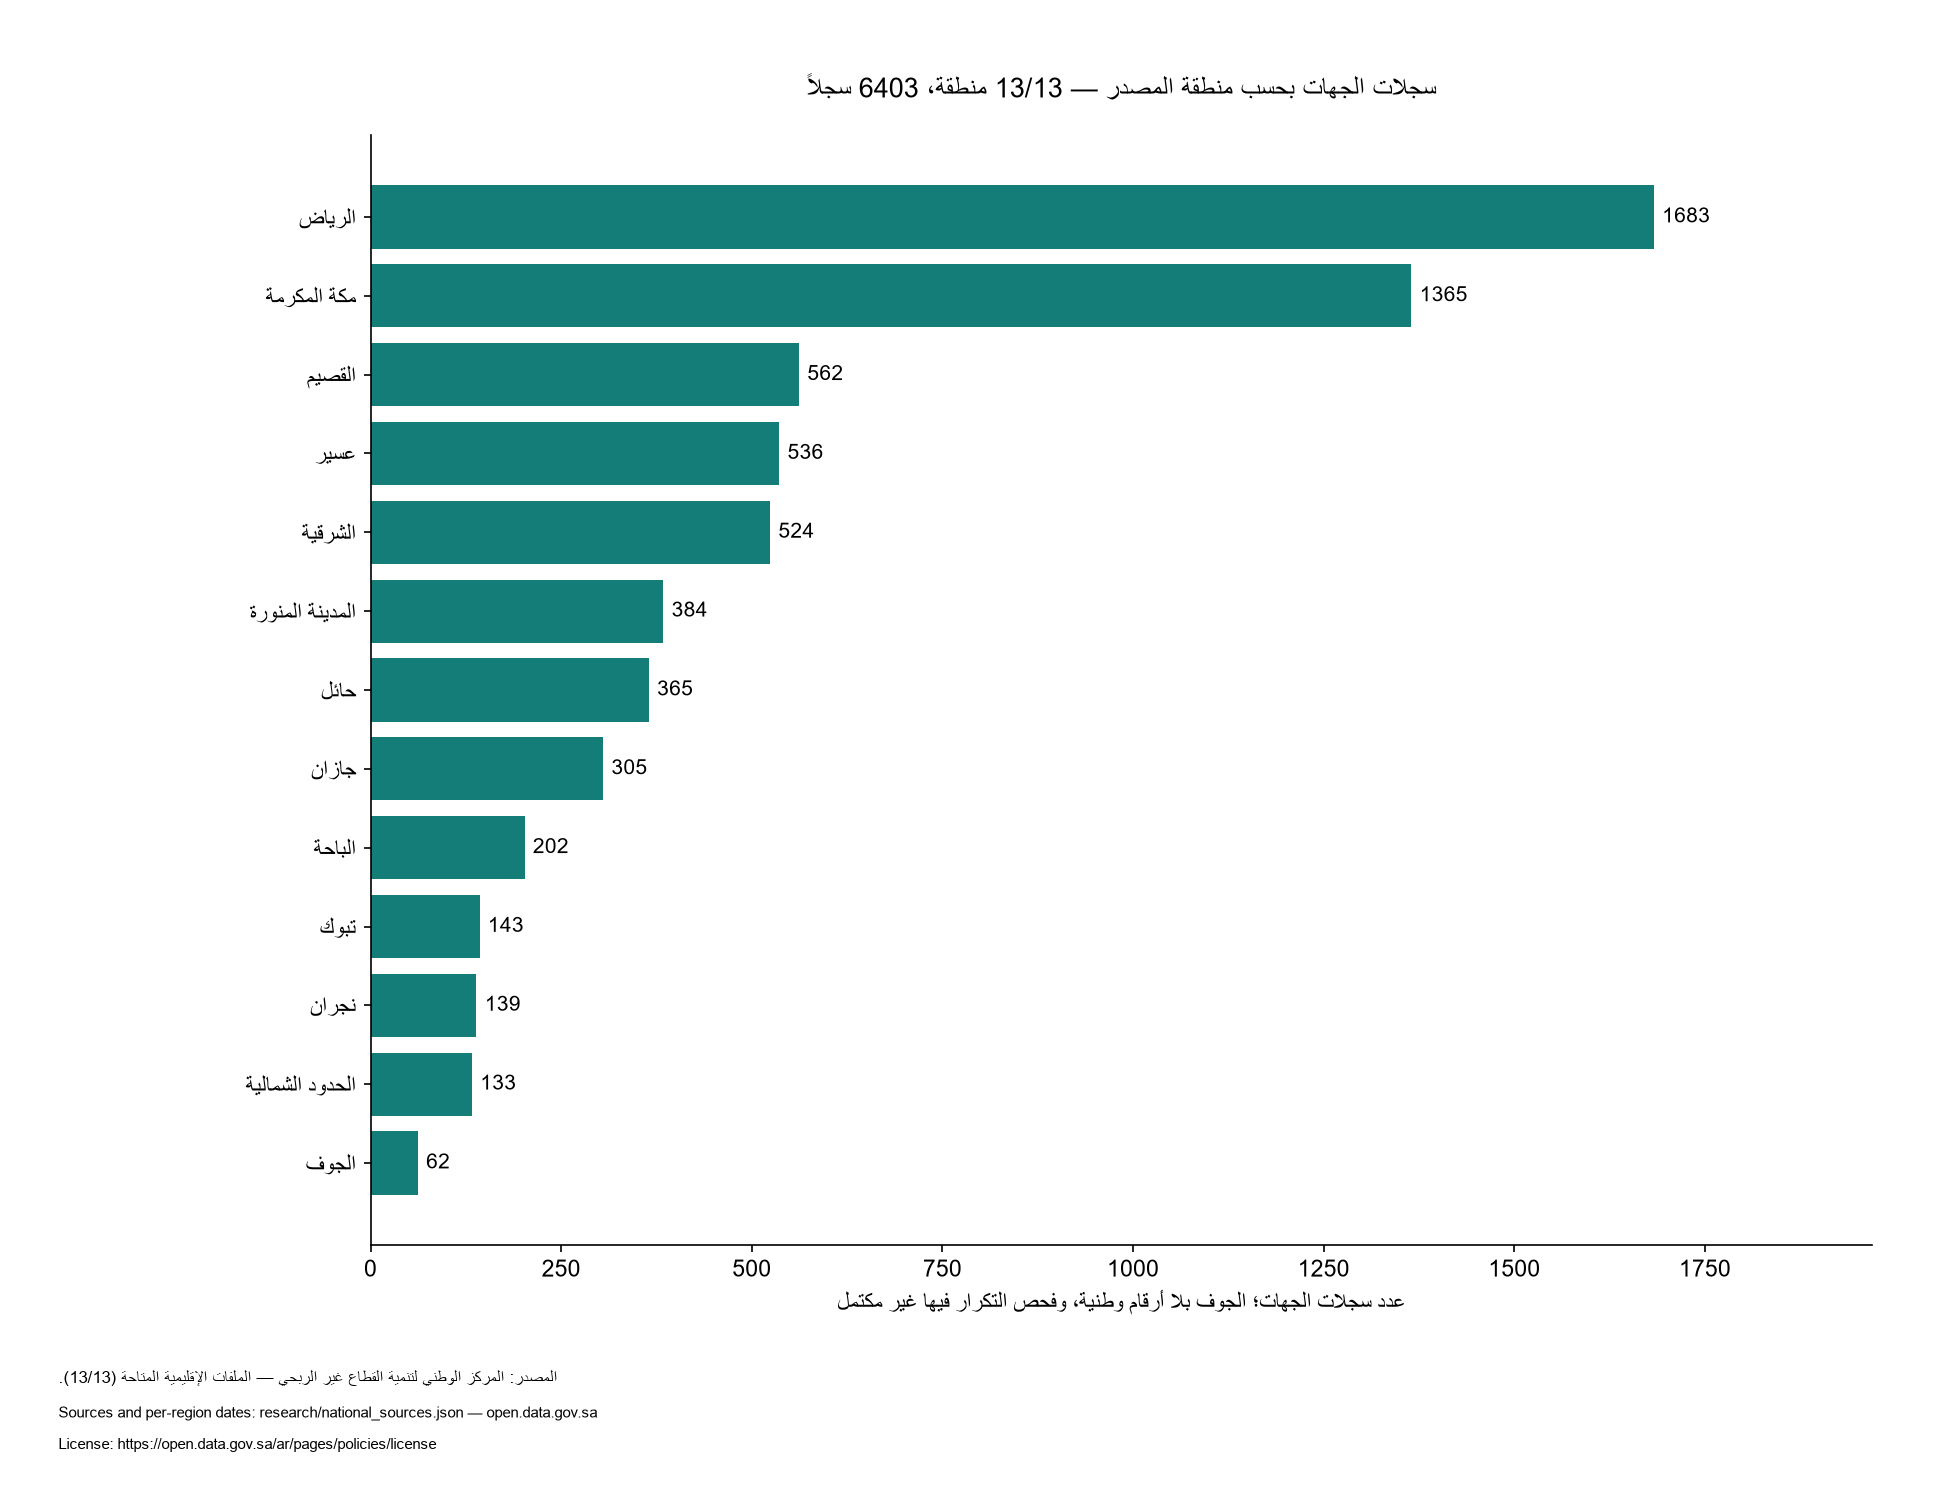

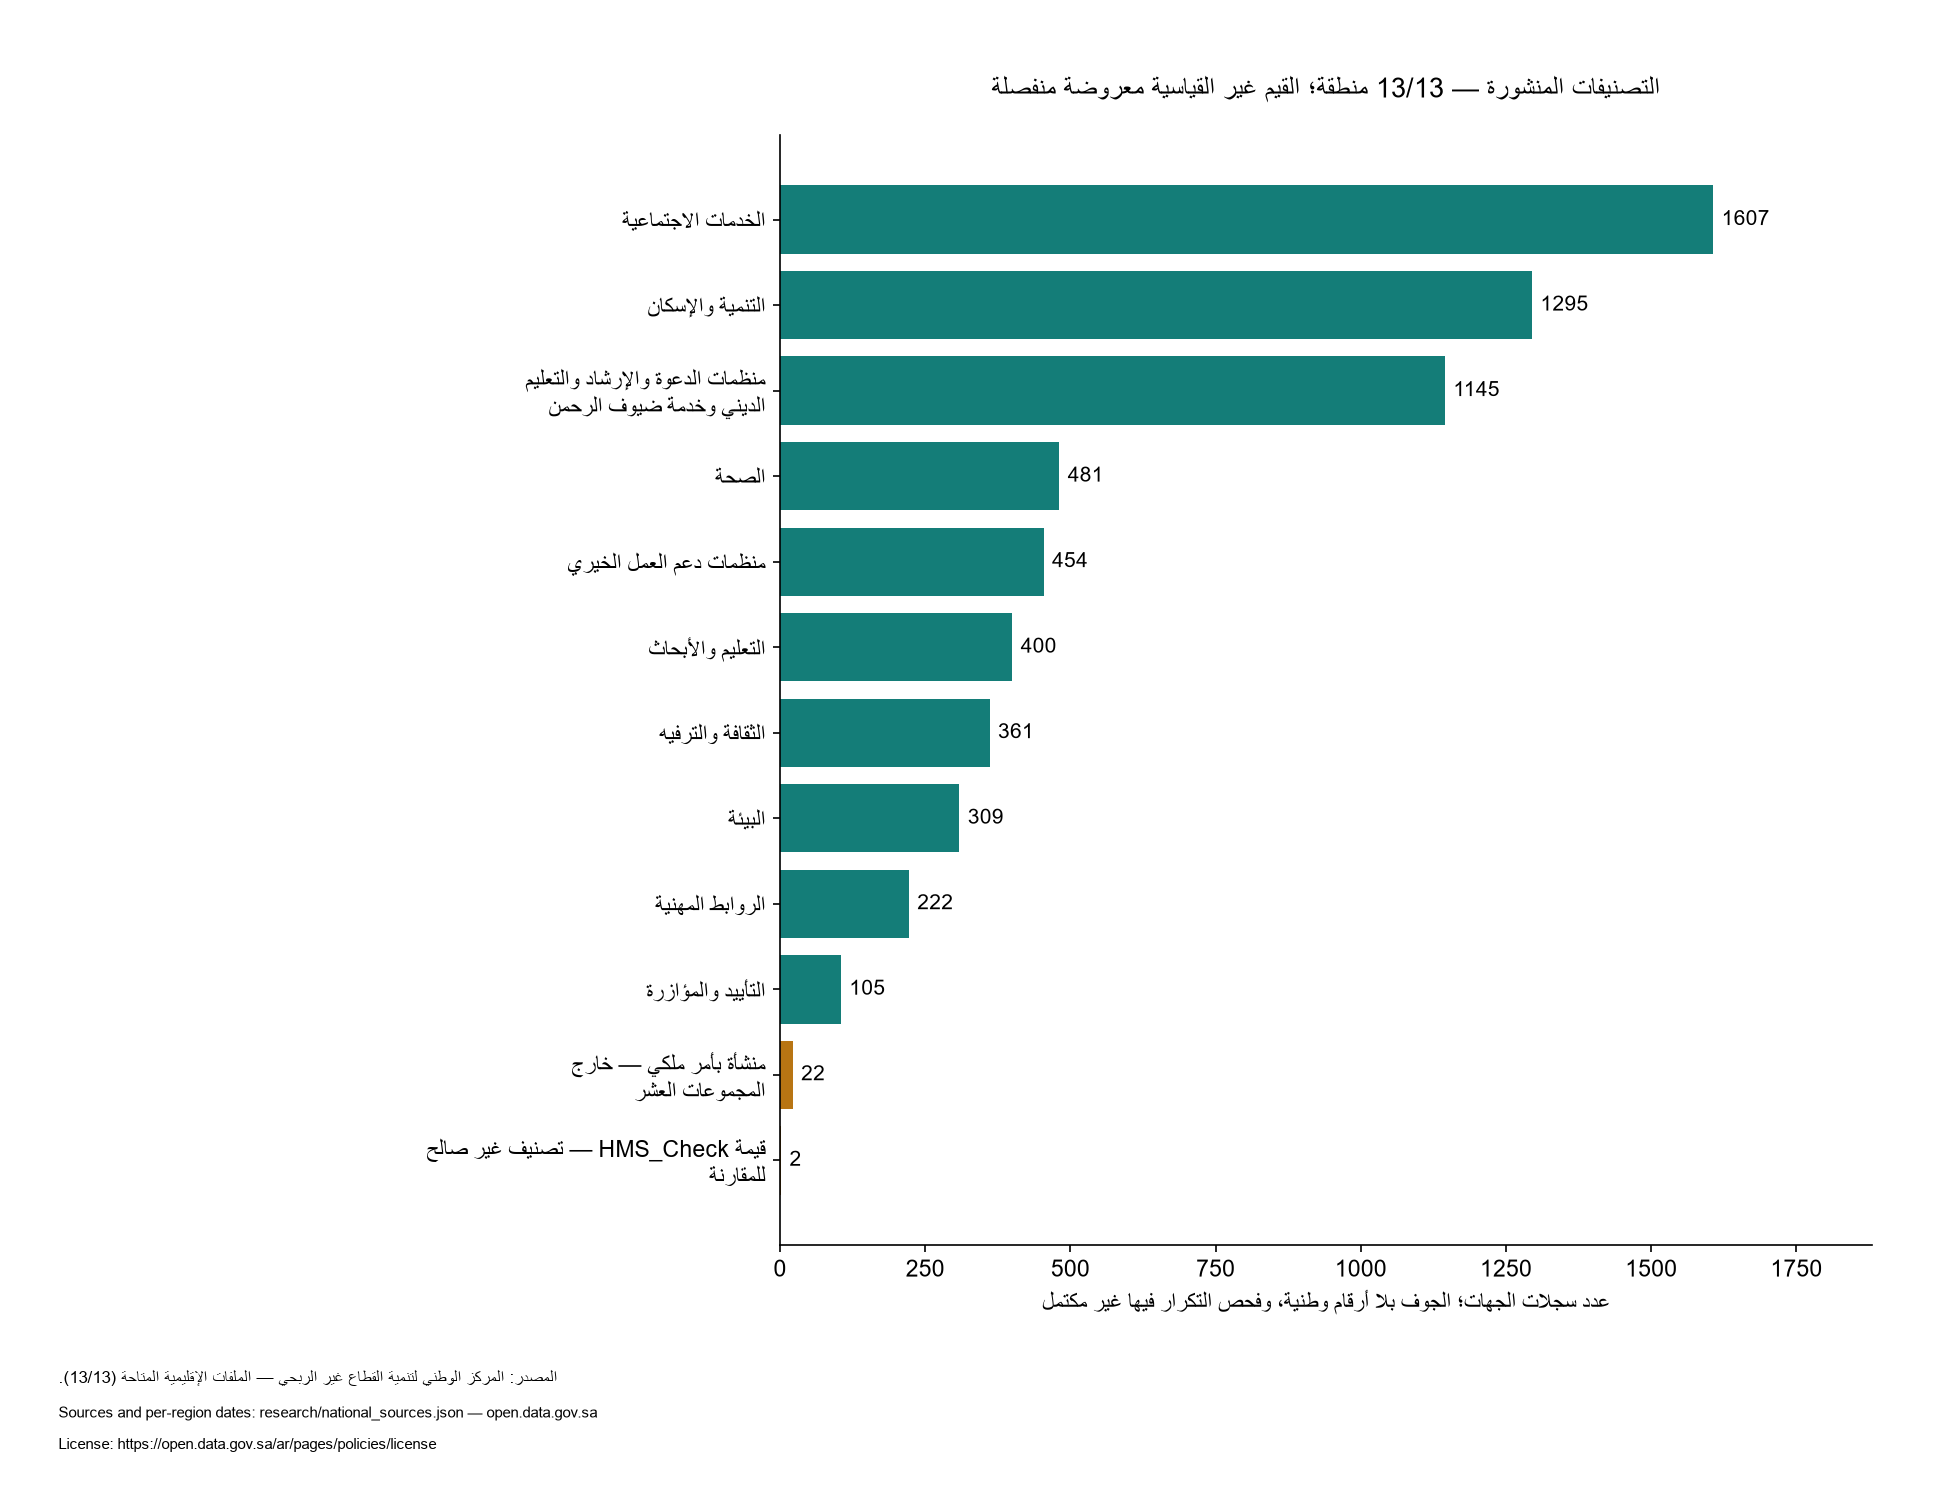

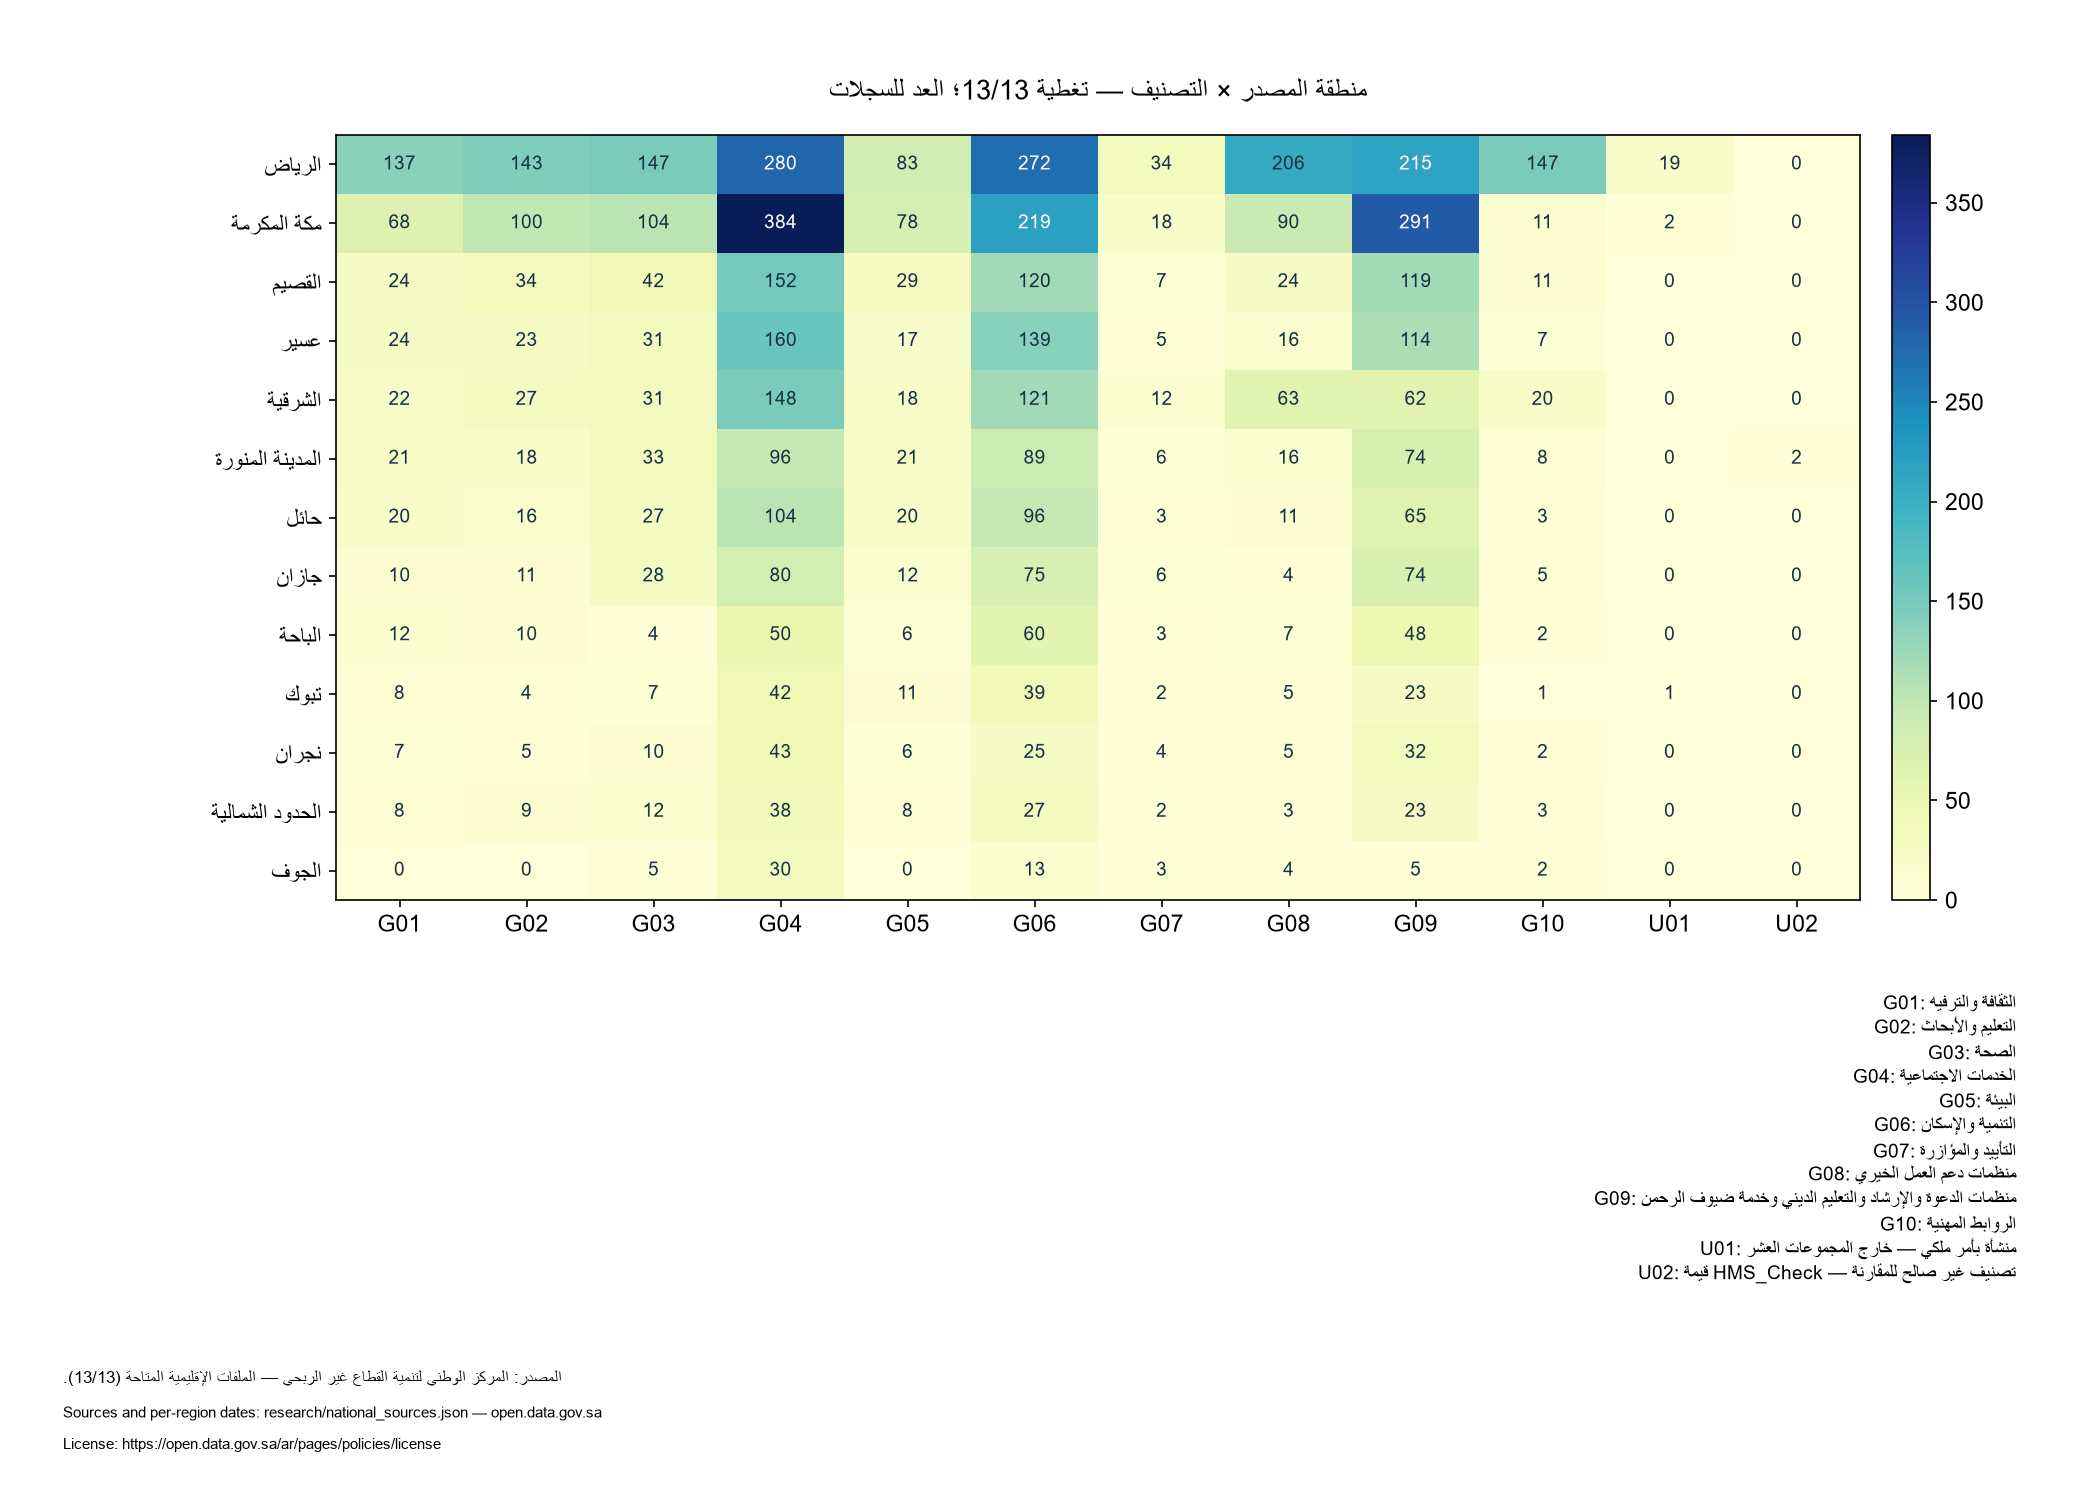

,region,location_label,locality_unit,entity_count,share_percent,denominator,covered_regions,expected_regions
58,الجوف,سكاكا,غير مذكور في المصدر,22,0.34,6403,13,13
97,الجوف,القريات,غير مذكور في المصدر,13,0.20,6403,13,13
122,الجوف,دومة الجندل,غير مذكور في المصدر,8,0.12,6403,13,13
129,الجوف,طبرجل,غير مذكور في المصدر,7,0.11,6403,13,13
154,الجوف,الأضارع,غير مذكور في المصدر,2,0.03,6403,13,13
155,الجوف,الناصفة,غير مذكور في المصدر,2,0.03,6403,13,13
156,الجوف,صوير,غير مذكور في المصدر,2,0.03,6403,13,13
159,الجوف,أبو عجرم,غير مذكور في المصدر,1,0.02,6403,13,13
160,الجوف,الجوف,غير مذكور في المصدر,1,0.02,6403,13,13
161,الجوف,الرياض,غير مذكور في المصدر,1,0.02,6403,13,13


,region,main_group_code,main_group_name,entity_count,region_denominator,share_within_region_percent
10,الجوف,G03,الصحة,5,62,8.06
11,الجوف,G04,الخدمات الاجتماعية,30,62,48.39
12,الجوف,G06,التنمية والإسكان,13,62,20.97
13,الجوف,G07,التأييد والمؤازرة,3,62,4.84
14,الجوف,G08,منظمات دعم العمل الخيري,4,62,6.45
15,الجوف,G09,منظمات الدعوة والإرشاد والتعليم الديني وخدمة ضيوف الرحمن,5,62,8.06
16,الجوف,G10,الروابط المهنية,2,62,3.23


In [15]:
figures=national_figures(ROOT,tables,inventory,manifest)
from IPython.display import Image,display
for path in figures:
    display(Image(filename=str(path),width=1100))
SELECTED_REGION="الجوف"
if SELECTED_REGION not in set(cleaned.region):
    print("لا يوجد ملف مقروء لهذه المنطقة:",SELECTED_REGION)
else:
    display(tables["locations"].query("region == @SELECTED_REGION"))
    display(tables["main_groups_within_region"].query("region == @SELECTED_REGION"))

<div dir="rtl">

## 7. حفظ المخرجات

النسخة الجديدة في `data_clean/national_entities_available.csv` و`outputs/national/`. مخرجات القصيم السابقة تبقى مستقلة.

نحفظ سجل التغييرات والمشكلات ونتائج الفحوص والروابط والمقام المستخدم. ملفات CSV تحفظ المعرّفات نصوصاً؛ يُفضّل استيرادها كنص عند فتحها في برنامج جداول.

</div>

In [16]:
def export_national(root,raw,cleaned,changes,issues,inventory,tables,checks,manifest):
    folder=root/"outputs/national"
    for relative in ["tables","quality"]:
        (folder/relative).mkdir(parents=True,exist_ok=True)
    destination=root/"data_clean/national_entities_available.csv"
    cleaned.to_csv(destination,index=False,encoding="utf-8-sig")
    reloaded=pd.read_csv(destination,dtype=str,keep_default_na=False,encoding="utf-8-sig")
    if reloaded.entity_id.tolist()!=cleaned.entity_id.tolist():
        raise AssertionError("CSV identifier roundtrip failed")
    checks["csv_identifier_roundtrip"]=True
    inventory.to_csv(folder/"tables/source_inventory_13_regions.csv",index=False,encoding="utf-8-sig")
    for name,table in tables.items():
        table.to_csv(folder/f"tables/{name}.csv",index=False,encoding="utf-8-sig")
    changes.to_csv(folder/"quality/text_changes.csv",index=False,encoding="utf-8-sig")
    issues.to_csv(folder/"quality/review_issues.csv",index=False,encoding="utf-8-sig")
    issue_counts={str(k):int(v) for k,v in issues.issue_code.value_counts().items()}
    coverage={"catalogued":13,"readable":int(inventory.status.eq("readable").sum()),
              "unavailable_regions":inventory.loc[inventory.status.ne("readable"),"region"].tolist(),
              "complete":bool(inventory.status.eq("readable").all()),"scope":"Regional publication availability only; not registry completeness."}
    report={"coverage":coverage,"records":len(cleaned),"entity_types":{str(k):int(v) for k,v in cleaned.entity_type.value_counts().items()},
            "unique_published_national_ids":int(cleaned.loc[cleaned.has_national_id,"entity_id"].nunique()),
            "records_with_national_id":int(cleaned.has_national_id.sum()),"records_without_national_id":int((~cleaned.has_national_id).sum()),
            "complete_national_entity_deduplication":bool(cleaned.has_national_id.all()),
            "counting_unit":"Source entity record. Records without a published national identifier are not nationally deduplicated.",
            "checks":checks,"issue_counts":issue_counts,
            "entities_with_review_issues":int(cleaned.needs_review.sum()),"standard_main_records":int(cleaned.standard_main_group.sum()),
            "source_cells_unchanged":True,"observation_scope":"Available regional publications; not a simultaneous or complete national census.",
            "subcategory_1_comparison_excludes":"makkah: all 1365 source rows have identical first/second subcategory values; publisher review needed."}
    (folder/"quality/quality_report.json").write_text(json.dumps(report,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
    (folder/"source_links.json").write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+"\n",encoding="utf-8")
    return report


def run(root=None,require_all_regions=True):
    root=Path(root) if root else project_root()
    verify_source_pairs(root)
    raw,inventory,manifest=load_sources(root,require_all_regions)
    rules=json.loads((root/"config/national_mappings.json").read_text(encoding="utf-8"))
    cleaned,changes,issues=normalize_national(raw,rules)
    checks=check_national(root,raw,cleaned,inventory,manifest)
    tables=summarize_national(cleaned,inventory)
    figures=national_figures(root,tables,inventory,manifest)
    report=export_national(root,raw,cleaned,changes,issues,inventory,tables,checks,manifest)
    return {"raw":raw,"cleaned":cleaned,"changes":changes,"issues":issues,"inventory":inventory,"tables":tables,"figures":figures,"report":report}

In [17]:
report=export_national(ROOT,raw,cleaned,changes,issues,inventory,tables,checks,manifest)
display(pd.Series(report["coverage"],name="التغطية").to_frame())
print("NATIONAL_AVAILABLE_NOTEBOOK_OK")
print("التغطية الجغرافية 13/13؛ فحص التكرار بالأرقام الوطنية يشمل السجلات التي نشرت معرّفاتها فقط.")

,التغطية
catalogued,13
readable,13
unavailable_regions,[]
complete,True
scope,Regional publication availability only; not registry completeness.


NATIONAL_AVAILABLE_NOTEBOOK_OK
التغطية الجغرافية 13/13؛ فحص التكرار بالأرقام الوطنية يشمل السجلات التي نشرت معرّفاتها فقط.


<div dir="rtl">

## 8. القراءة والمرحلة التالية

أضيفت عسير بـ536 سجلًا والجوف بـ62 بعد مقارنة الصيغتين بالكامل. أصبح التحليل يغطي منشورات المناطق الـ13، مع 6,341 معرّفاً منشوراً فريداً و62 سجلًا بلا معرّف. هذه تغطية للمنشورات الإقليمية وليست دليلاً على اكتمال سجل وطني متزامن.

تبقى مراجعة تصنيفي مكة والقيم التقنية والمواقع المتعارضة، والبحث عن معرّفات الجوف من مصدر رسمي إذا أردنا إزالة تكرار وطنية شاملة. لم نربط الكيانات اعتماداً على تشابه الأسماء.

لا نقترح ترتيباً للاحتياج أو توقعاً زمنياً من هذه اللقطات. الخطوة التالية تحديد تخصص وقرار قابل للقياس، ثم البحث عن بيانات سكان ومؤشرات مناسبة قبل توصيات التوسع.

</div>